<div style="background:#15324f;color:white;padding:26px 30px;border-radius:12px">
<div style="color:#89e0df;letter-spacing:2px;font-size:12px">IAHR Training Course on AI Tools for Transient Flow Analyses</div>
<h1 style="color:white;margin:12px 0">Graph Neural Networks<br>for Passive Transient Source Localisation</h1>
<p style="color:#d4e4ef">Dr. M Waqar · Hong Kong Metropolitan University</p>
</div>

**The question:** pressure sensors recorded a disturbance. Which pipe did it start in, and where along that pipe?

**The Method:** Today we will learn how GNNs can be used to answer the above question through a worked engineering example. The goal is to understand the ingredients and how they connect.

**Learning Outcome:** By the end, you will connect a physical pipe network to a graph, interpret node features and embeddings, follow message passing, and build a GNN with two outputs. 

## 0. Prepare the experiment
- See [README.md](README.md) for the fresh Conda installation.
- Select the **Python (IAHR GNN HKUST Tutorial)** kernel. 
- **Shift + Enter** runs one cell. **Kernel → Restart Kernel and Run All Cells** starts a complete run.
- To retrian the model, set `RETRAIN=False` to `RETRAIN=True` and choose the maximum number of epochs. The setup then trains once and the rest of this notebook uses that newly trained model.
- The files are stored in `outputs/`, preserving the supplied model.
- `DEVICE='auto'` uses a working CUDA GPU when available; otherwise CPU.
- The default ten sensors use their original EPANET names. A different sensor list or source-pipe threshold requires `RETRAIN=True`.
- Changing the split seed or counts also requires new hydraulic test sources.

In [1]:
from pathlib import Path
import time, warnings, sys
warnings.filterwarnings('ignore', message='pkg_resources is deprecated.*')
warnings.filterwarnings('ignore', message='Not all curves were used.*')
warnings.filterwarnings('ignore', message='Changing the headloss formula from H-W to D-W.*')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from matplotlib_inline.backend_inline import set_matplotlib_formats
from graph_tools import (load_network, make_source_split, travel_times,
    relative_times, add_timing_noise, network_error, ambiguity_report)
from model import GraphSourceGNN, train_model, load_model, save_model, predict
from run_experiments import load_test_set, evaluate
import tutorial_ui as ui
import signal_ui as signals
from signal_story import observe_event, arrival_table

STARTED = time.perf_counter()
ROOT = Path.cwd()
assert (ROOT / 'networks/HKUST.inp').exists(), 'Open this notebook inside the extracted project folder.'


# MAIN CONTROLS. Change them here, then restart the kernel and run all cells.
RETRAIN = False
TRAINING_EPOCHS = 500
DEVICE = 'auto'
SENSOR_NODES = None  # None will use the default 10 sensors stored in the INP file; TO define here, use ['J10', 'J84', 'J102']
MIN_SOURCE_PIPE_LENGTH = 100.0  # metres; all pipes still carry waves in the graph
SAMPLING_HZ = 100.0
TIMING_STD_S = 0.010            # independent Gaussian timestamp uncertainty
TIME_QUANTUM_S = 1.0 / SAMPLING_HZ
BACKGROUND_STD_M = 0.005       # head-noise standard deviation for the signal demonstration
EXTRA_PICK_JITTER_MS = 10.0    # separate from the error caused by waveform noise
SHOW_NODE_IDS = False  # enable for the full map; focused neighbourhoods show IDs
SHOW_PIPE_IDS = False

# Small graphs benefit from limiting CPU thread overhead.
torch.set_num_threads(2)
ui.style()
set_matplotlib_formats('png')
net = load_network(sensors=SENSOR_NODES, min_source_pipe_length=MIN_SOURCE_PIPE_LENGTH)
splits = make_source_split(net, train_per_pipe=48, val_per_pipe=12, test_per_pipe=2, seed=2026)
tsdata = load_test_set(net, splits=splits)

# Retrain the model
if RETRAIN:
    gnn, history = train_model(net, splits['train'], splits['val'],
                               epochs=TRAINING_EPOCHS, sigma=TIMING_STD_S, quantum=TIME_QUANTUM_S,
                               seed=42, hidden=32, layers=3, batch_size=128, learning_rate=0.002,
                               position_weight=4.0, patience=30, device=DEVICE, threads=2,
                               checkpoint_path=ROOT/'outputs/training_last.pt', resume=False, print_every=10)
    save_model(gnn, ROOT/'outputs/gnn_user.npz', history=history)
else:
    if TIMING_STD_S != 0.010 or TIME_QUANTUM_S != 0.010:
        raise ValueError('The supplied model was trained with 10 ms Gaussian jitter and 100 Hz timestamps. Set RETRAIN=True for a new training noise setting.')
        
    gnn = load_model(net, ROOT/'models/gnn_demo.npz', device=DEVICE)
    history = gnn.history
print(f'Ready | {next(gnn.parameters()).device} | {net.N} nodes | {net.P} physical pipes | {net.S} sensors')
print(f'Eligible source pipes: {net.source_pipe_count} (length >= {MIN_SOURCE_PIPE_LENGTH:g} m)')
print('Sensor order:', ', '.join(net.sensors))
print('Training / validation / held-out graph locations:', *(len(splits[s]['pipe']) for s in ('train','val','test')))
print('Active model:', 'newly trained model in outputs/' if RETRAIN else 'prepared teaching model')
print(f'Setup completed in {time.perf_counter()-STARTED:.1f} seconds.')

TSNet sources: retained 21/21 cached events; excluded 0 below 100 m.


Ready | cpu | 31 nodes | 33 physical pipes | 10 sensors


Eligible source pipes: 21 (length >= 100 m)


Sensor order: J10, J84, J102, J107, J88, J62, J79, J46, J16, J51


Training / validation / held-out graph locations: 1008 252 42


Active model: prepared teaching model


Setup completed in 0.1 seconds.


### The physical network

- The model below is adapted from the HKUST freshwater network.
- It contains **30 junctions and the fixed-head boundary T1**, connected by **33 pipes**.
- The GNN retains all 31 nodes.
- T1 is represented as a 40 m head reservoir in this controlled hydraulic example.
- Geographic coordinates are projected locally for drawing; travel times and distance errors use the measured pipe lengths.
- Potential source pipes are at least **100 m** long: 21 pipes meet that threshold. Shorter pipes remain in the network and in wave propagation. The threshold controls where a source may be placed, not which pipes physically exist.

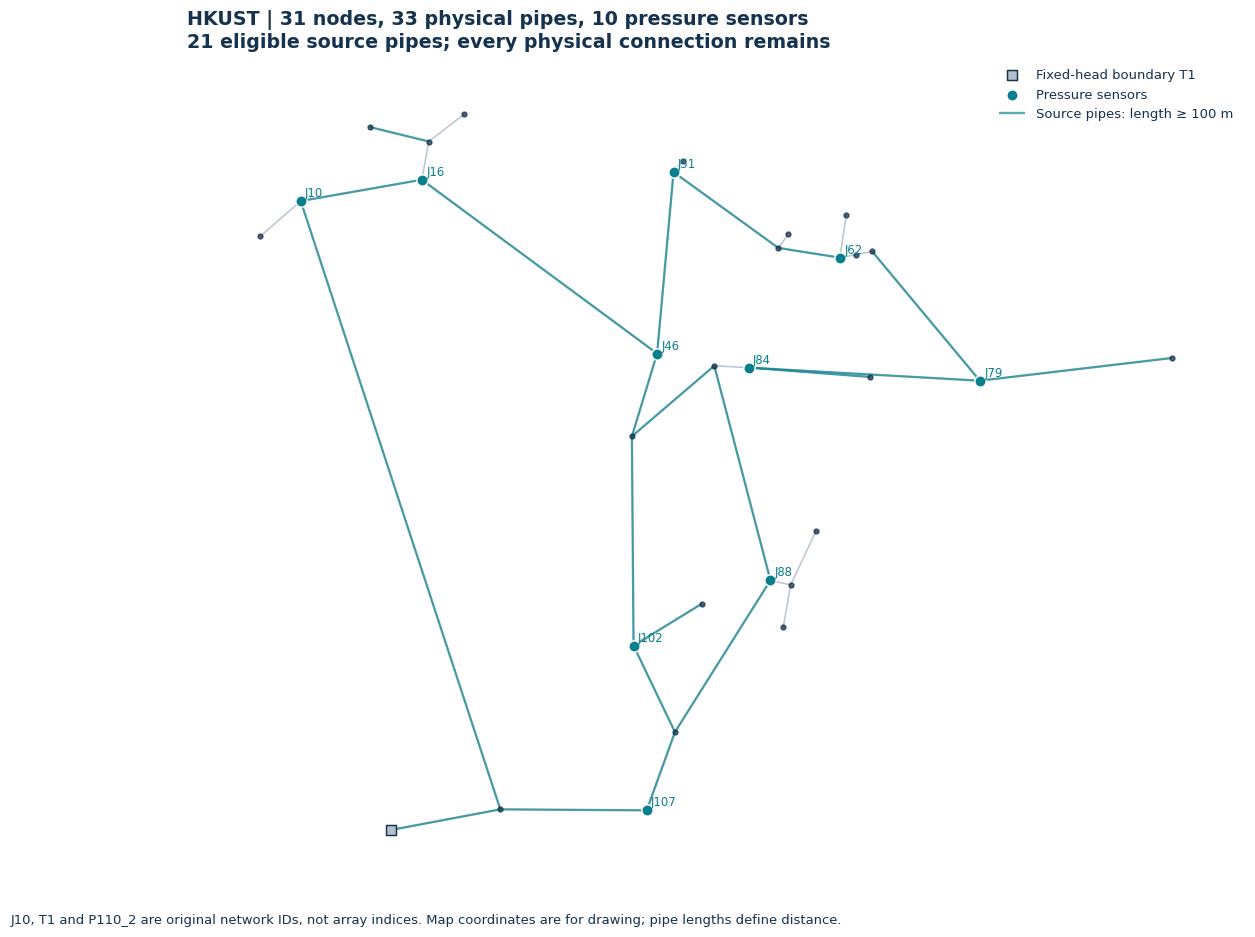

Accordion(children=(VBox(children=(HTML(value='<b>Read the same network at two scales.</b> Labels preserve the…

In [2]:
fig = ui.plot_network(net, show_node_ids=SHOW_NODE_IDS, show_pipe_ids=SHOW_PIPE_IDS)
display(fig); plt.close(fig)
display(ui.panel(ui.network_explorer(net), 'Explore interactively: network and labels'))

## 1. We have a pressure signal. Where did it come from?

A burst (or passive transient activity) excites a pressure transient wave in the network. Waves travel through the connected pipes and reach the sensors at different times. **Passive monitoring** observes these events without imposing a diagnostic excitation.

Our sensors sit at existing junctions. The burst may start **inside any eligible pipe**. Its location and onset time are unknown to the localisation model.

The first display hides the simulated source. Inspect the waveforms and identify what information a sensor actually provides. The pressure-head axis is in metres of water; this is a pressure measurement expressed as head.

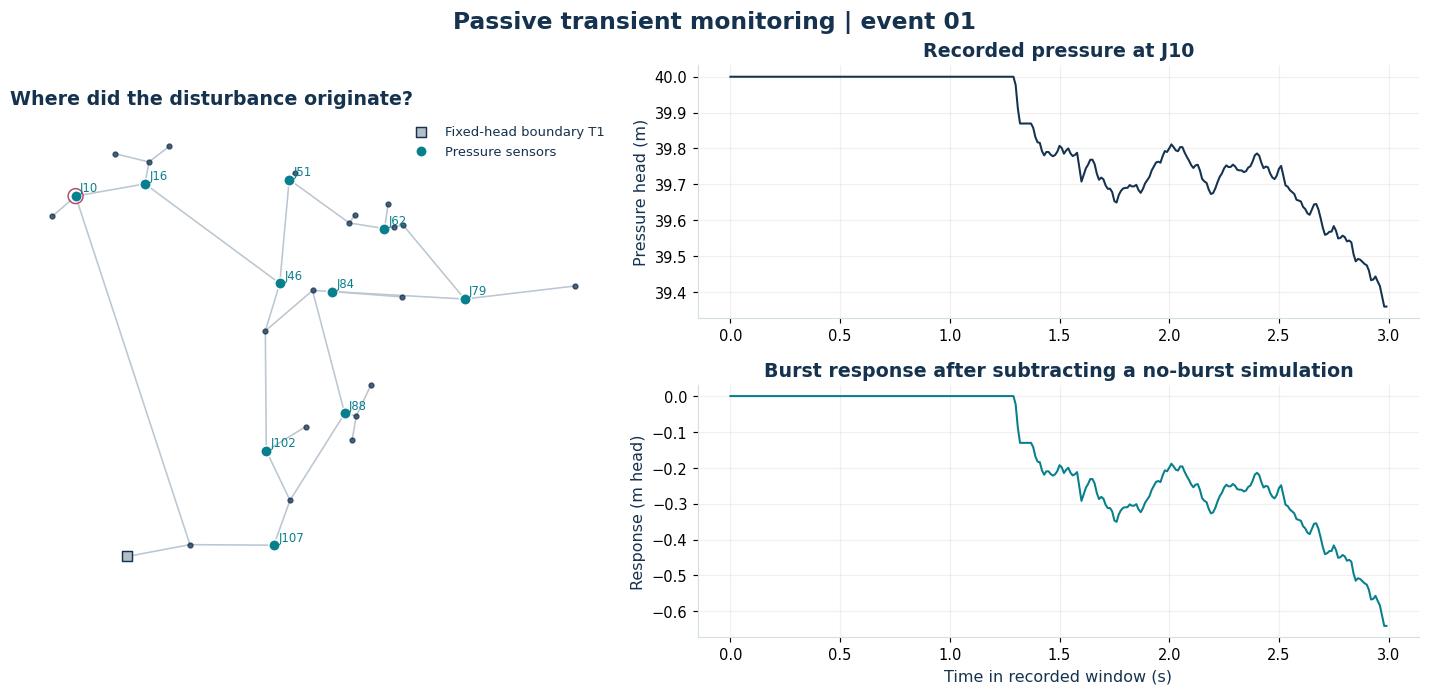

Accordion(children=(VBox(children=(HTML(value='<b>Start with the observation.</b> The event occurs without a d…

In [3]:
fig = signals.plot_mystery(net, tsdata, index=0, sensor=0, reveal=False)
display(fig); plt.close(fig)
display(ui.panel(signals.mystery_explorer(net, tsdata), 'Explore interactively: the unknown event'))

## 2. What is a graph?

Write a graph as $G=(V,E)$: $V$ is its set of nodes and $E$ its set of edges. A weighted graph additionally assigns a value $w_e$ to each edge.

| Concept | Meaning in this tutorial |
|---|---|
| Node | A junction or boundary connection |
| Edge | A physical connection between two nodes |
| Neighbours | Nodes directly connected to the chosen node |
| Degree | Number of neighbouring nodes |
| Path | A sequence of connected edges |
| Hop | Crossing one edge, regardless of its physical length |
| Weight | A specified property, such as length or travel time |

We use an undirected graph because pressure disturbances travel in both directions, neglecting mean-flow advection. This retained network contains pipe connections and a fixed-head supply boundary.

### Store connectivity in a matrix

$$A_{ij}=\begin{cases}1,&\text{an open connection joins }i\text{ and }j,\\0,&\text{otherwise.}\end{cases}$$

The full matrix is $31\times31$. Start with a small neighbourhood taken from **this same network**. Follow one row of the matrix back to the connected nodes. The initial diagonal is zero; self-connections enter the GNN later.

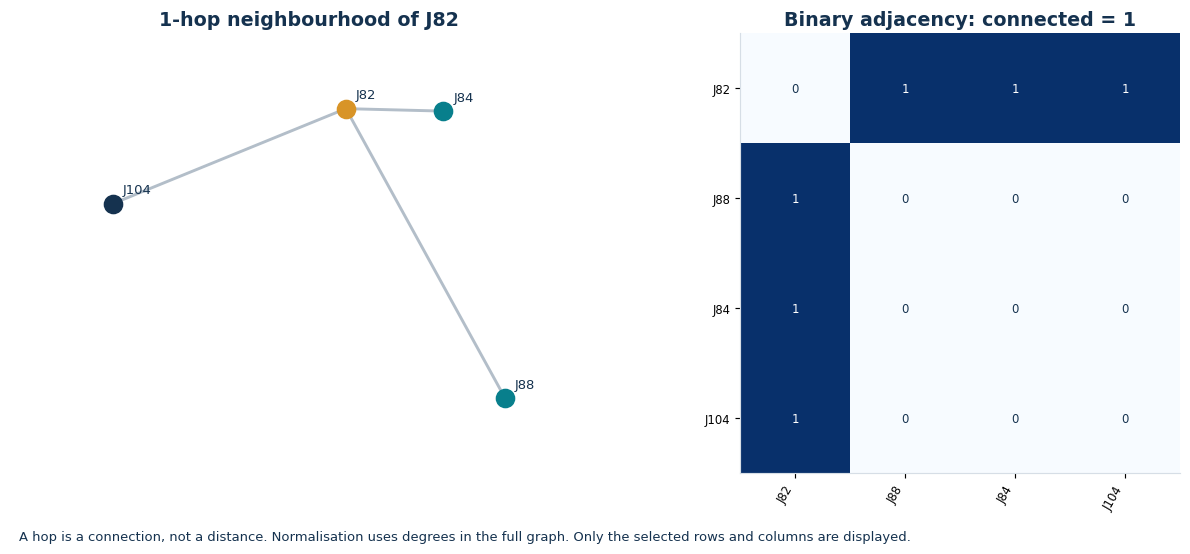

Accordion(children=(VBox(children=(HTML(value='<b>Two different uses of a graph.</b> Adjacency tells the GNN w…

In [4]:
fig = ui.plot_adjacency(net, node_name='J82', hops=1)
display(fig); plt.close(fig)
display(ui.panel(ui.adjacency_explorer(net), 'Explore interactively: graph ↔ adjacency'))

## 3. Give the graph a physical meaning

A wave crossing pipe $e$ of length $L_e$ at speed $a_e$ takes

$$w_e=\frac{L_e}{a_e}\quad\text{seconds}.$$

The path with the smallest sum of these costs gives the earliest predicted travel time. For a source at fraction $\xi$ from pipe endpoint $u$ towards endpoint $v$, waves can leave in either direction:

$$T_s(e,\xi)=\min\left[\frac{\xi L_e}{a_e}+D(u,s),\;\frac{(1-\xi)L_e}{a_e}+D(v,s)\right]$$

Here $D(u,s)$ is the shortest travel time from endpoint $u$ to sensor $s$ (calculated using Dijkstra's algorithm). It is defined as

$$
D(u,s)=
\min_{\mathcal P:u\rightarrow s}
\sum_{(i,j)\in\mathcal P}\frac{L_{ij}}{a_{ij}}
$$

A source halfway along the pipe has $\xi=0.5$.

**What the prior describes:** first-arrival timing. The full waveform also contains amplitudes, reflections and interactions at boundaries. Moving the source changes its timing signature even though the network topology stays fixed.

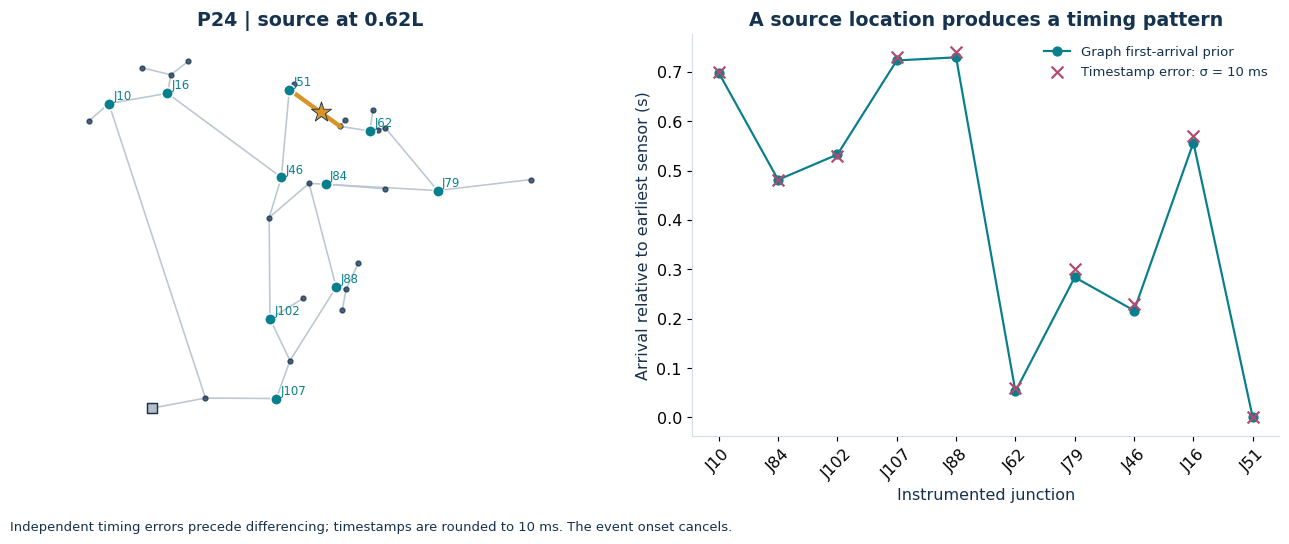

Accordion(children=(VBox(children=(HTML(value='Move a source continuously within an eligible pipe. The random …

In [5]:
pipe = int(tsdata['pipe'][0])
xi = float(tsdata['xi'][0])  # reveal the same event used in the opening scene
clean_times = travel_times(net, [pipe], [xi])
observation = relative_times(add_timing_noise(clean_times, TIMING_STD_S,
    TIME_QUANTUM_S, np.random.default_rng(12)))
fig = ui.plot_travel(net, pipe=pipe, xi=xi, sigma_ms=1000*TIMING_STD_S)
display(fig); plt.close(fig)
display(ui.panel(ui.source_explorer(net), 'Explore interactively: source position and travel times'))

### Check the travel-time graph knowledge against a MOC-based transient signal

For this explanatory overlay only, the event onset $t_0$ is known from the simulation, so the vertical line is $t_0+T_s$. **The localisation model never receives that onset or the source label.** We will remove the unknown onset from its inputs.

The stored pressure responses are sampled at **100 Hz**, so one sample spans **10 ms**. Differences between the vertical lines may reflect sampling, the detector's threshold crossing, and differences between the graph approximation and the hydraulic simulation.

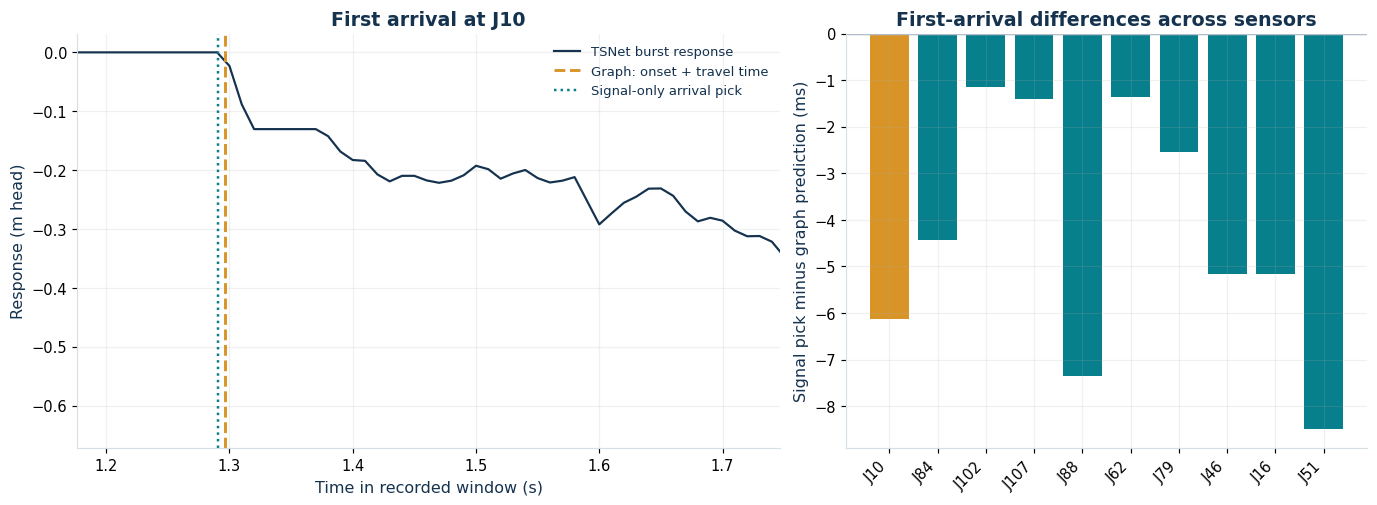

Accordion(children=(VBox(children=(HTML(value='<b>Check the first-arrival prior.</b> Dashed lines use the know…

In [6]:
fig = signals.plot_arrival_overlay(net, tsdata, index=0, sensor=0)
display(fig); plt.close(fig)
display(ui.panel(signals.arrival_explorer(net, tsdata), 'Explore interactively: predicted and picked arrivals'))

<details><summary><b>Physical and numerical details</b></summary>

- T1 is a fixed-head boundary in this TSNet setup.
- The controlled hydraulic model starts from zero demands and zero junction elevations, with a 40 m supply head and a fixed Darcy friction factor of 0.02.
- Nominal wave speeds use a ductile-iron K9 wall model with each pipe diameter, giving approximately 1,137–1,231 m/s. TSNet adjusts these speeds during discretisation. The prior uses effective speeds computed once on the original **unsplit** network with a requested 1.04045 ms step, before any source is chosen.
- Raw pressure heads remain available in the signal tabs.
</details>

## 4. What changes when the observation is uncertain?

A clean leading edge can be easy to pick. Background pressure noise changes the trace and can change the detected arrival. An analyst or detector may introduce further timestamp uncertainty.

We will explore these separately:

1. **Background noise:** add independent Gaussian head noise, in metres, to each sensor's pressure response and rerun the detector.
2. **Additional picking uncertainty:** perturb the detected timestamps with independent Gaussian errors, in milliseconds, then round them to the sampling grid.

**The learning question:** can the GNN learn useful location patterns from many observations with uncertainty? The training examples will include timing perturbations. The GNN in this notebook consumes the resulting timing features, not the raw waveform.

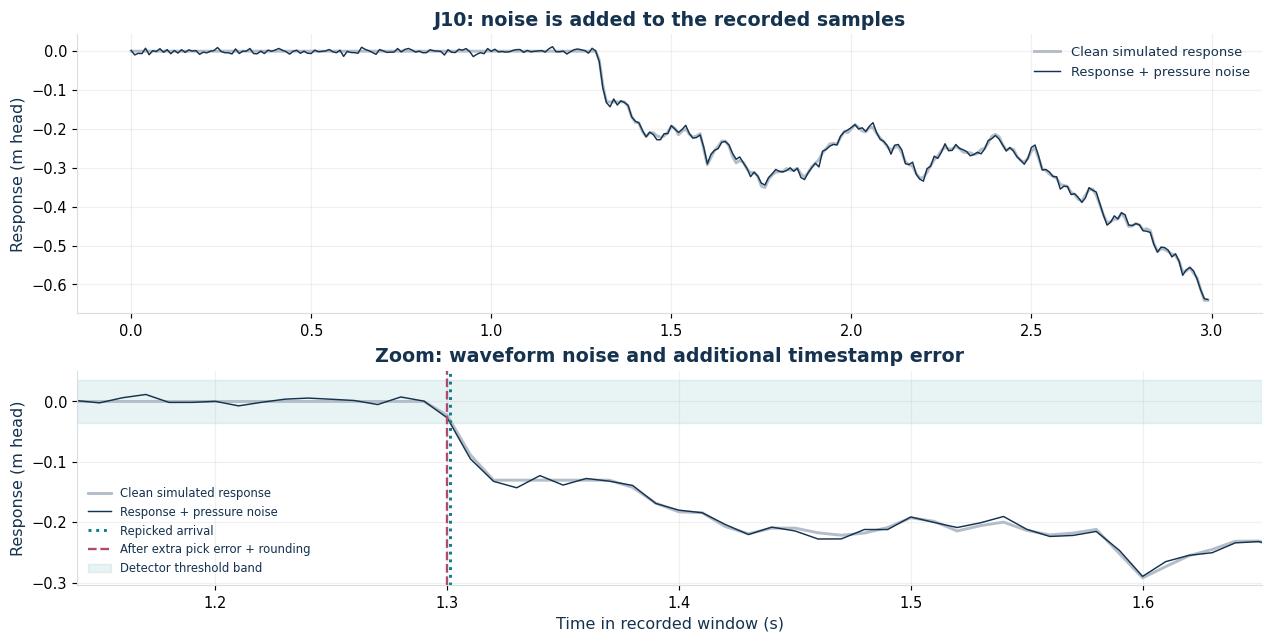

Accordion(children=(VBox(children=(HTML(value='<b>Two distinct uncertainty sources.</b> Noise σ changes pressu…

In [7]:
fig = signals.plot_uncertainty(net, tsdata, index=0, sensor=0,
    noise_std_m=BACKGROUND_STD_M, jitter_ms=0.0, seed=42)
display(fig); plt.close(fig)
display(ui.panel(signals.uncertainty_explorer(net, tsdata, noise_std_m=BACKGROUND_STD_M, jitter_ms=0.0, seed=42), 'Explore interactively: noise → picks → timing features'))

### Remove the unknown start time

An observed timestamp can be written as $t_s=t_0+T_s+\epsilon_s$. Subtracting the earliest observed arrival removes the common, unknown $t_0$:

$$\Delta t_s=t_s-\min_r t_r.$$

Noise is added to the individual timestamps **before** this operation. The individual draws are independent, but the resulting relative-time errors share a reference and therefore need not be independent. The model internally mean-centres the timing vector as well; a common shift contains no location information here.

At 100 Hz, a one-sample error is 10 ms. A signed error of 2–10 samples is 20–100 ms in magnitude, not a standard deviation of 2–10 ms. Our default training uncertainty is **10 ms standard deviation**, with 10 ms timestamp quantisation.

## 5. Features Become Embeddings

We now have two kinds of information: the known pipe network and the arrival times picked from the sensor signals. We need to organise this information into numbers that our neural network can process.

A **feature** is an input quantity whose meaning we specify. An **embedding** is a collection of numbers produced from those features by a learned transformation.

In this tutorial, the network has **31 graph nodes**, and **10 of those nodes have sensors**. We construct features for all 31 nodes, then transform each node's features into an embedding.

### 5.1 What information does each node receive?

Only the sensor nodes provide measured pressure signals. From these signals, we pick one arrival time per sensor, giving a vector of 10 observed arrival times:

$$
\mathbf t=[t_1,t_2,\ldots,t_{10}].
$$

The entries always follow the same sensor order. The model uses these arrival picks as its event measurements; it does not receive the complete pressure time series.

In our implementation, **every graph node receives this same vector of observed sensor timings**. This is a deliberate input design: each node has access to the event's overall timing pattern.

A node without a sensor therefore still has input features. Providing the measurements from other sensors does not create a measurement at that node.

To distinguish one node from another, we also provide information about its position and connections within the known network.

### 5.2 What is a graph landmark vector?

For a particular node $i$, we calculate the shortest graph travel time from that node to each sensor:

$$
\mathbf d_i=
[D(i,s_1),D(i,s_2),\ldots,D(i,s_{10})].
$$

Here, $D(i,s_j)$ is the shortest travel time from node $i$ to sensor $s_j$, calculated using the known pipe connections, lengths and wave speeds.

We call this the node's **graph travel-time reference**, or **landmark vector**. For an ordinary junction, it describes the first-arrival pattern predicted by the graph model if a disturbance started at that junction.

These reference vectors are calculated for all nodes without knowing where the observed burst occurred. For a fixed network and sensor arrangement, they stay the same across events.

The reference vector is different from an adjacency row: adjacency describes direct connections, whereas this vector describes travel times along paths to the sensors.

### 5.3 What does “observed minus landmark” mean?

We want to compare the observed timing pattern with each node's graph reference.

Before comparing them, the code subtracts each vector's own mean and divides both vectors by the same positive time scale, $\tau$, calculated from the network:

$$
\mathbf o=
\frac{\mathbf t-\operatorname{mean}(\mathbf t)}{\tau},
\qquad
\boldsymbol{\ell}_i=
\frac{\mathbf d_i-\operatorname{mean}(\mathbf d_i)}{\tau}.
$$

Subtracting the mean removes a common time offset, so the comparison does not require the burst's starting time. Dividing by the time scale gives dimensionless input values. Negative values are therefore normal: they indicate entries earlier than the vector's mean.

The difference vector for node $i$ is

$$
\mathbf r_i=\mathbf o-\boldsymbol{\ell}_i.
$$

Each entry compares the observation and reference for the **same sensor**.

For a small illustration using three sensors, suppose the vectors after centring and scaling are

$$
\mathbf o=[-0.2,\;0.1,\;0.1],
\qquad
\boldsymbol{\ell}_i=[-0.3,\;0.2,\;0.1].
$$

Then

$$
\mathbf r_i=[0.1,\;-0.1,\;0].
$$

The first observed entry is relatively later than the reference, the second is relatively earlier, and the third agrees. Our actual implementation performs this operation with 10 entries.

We also provide the elementwise squared differences:

$$
\mathbf r_i^2=[0.01,\;0.01,\;0].
$$

The signed differences retain the direction of disagreement. The squared differences describe its magnitude without the sign. Both are calculated features, not additional measurements.

**This comparison does not use the true source location.** The observed vector comes from the sensor picks, and the reference vectors come from the known graph. The source pipe and position remain unknown during prediction.

A small difference means that a node's reference resembles the observed timing pattern. It does not establish that the burst occurred at that node. The source may lie inside a pipe, and the model ultimately predicts a pipe and a position along it.

### 5.4 What are the 46 features at each node?

With 10 sensors, our implementation supplies the following inputs:

| Feature group | Number | Meaning |
|---|---:|---|
| Graph reference | 10 | The node's centred and scaled travel-time pattern to the sensors. |
| Observed timings | 10 | The centred and scaled sensor observations, supplied identically to every node. |
| Observed minus reference | 10 | The signed differences between those two patterns. |
| Squared differences | 10 | The elementwise squares of the differences. |
| Coordinates | 2 | The node's known physical $x$ and $y$ coordinates, centred and scaled. |
| Degree | 1 | The number of directly connected neighbouring nodes, divided by the largest degree in the graph. |
| Boundary flag | 1 | An indicator that a complete finite travel-time reference is unavailable. In this case, it marks the fixed-head supply node T1. |
| Sensor flag | 1 | `1` if the node contains a sensor; `0` otherwise. |
| Local timing | 1 | The node's own centred and scaled arrival pick if it has a sensor; otherwise a zero placeholder. |

Thus,

$$
F=10+10+10+10+2+1+1+1+1=46.
$$

Some distinctions matter:

- **Coordinates** describe the known location of the network node, not the unknown burst location and not the learned embedding.
- **Degree** counts immediate, one-hop neighbours. It does not count all reachable nodes or measure distance.
- **Flags** are numerical indicators. They tell the model which situation applies.
- **Local timing** is an arrival-time feature, not a pressure amplitude. At a sensor node, it repeats the corresponding entry from the full observed vector.
- A zero local timing at a nonsensor node means “no local measurement”. The sensor flag distinguishes this placeholder from a valid sensor value of zero.
- T1's unavailable graph-reference values are filled with zeros for computation. Its boundary flag distinguishes these placeholders from a physical travel-time prediction.

These are **46 input features per node**, not 46 independent sensor measurements.

For one event, we place the features into a matrix $X$ with one row per graph node:

$$
X\in\mathbb R^{31\times46}.
$$

The 31 rows represent network nodes. The 46 columns represent feature types. This feature matrix is not the adjacency matrix.

### 5.5 How do 46 features become 32 embedding values?

We choose an embedding width of **32**. This is a model setting, independent of the number of graph nodes.

The encoder applies a learned transformation to each row:

$$
H^{(0)}=\operatorname{GELU}(XW_{\mathrm{in}}+\mathbf b_{\mathrm{in}}),
$$

where $W_{\mathrm{in}}$ has shape $46\times32$ and the bias contains 32 values.

Each of the 32 output values is formed by taking a weighted sum of the 46 inputs, adding a bias, and applying GELU, a smooth nonlinear activation.

The same weights and biases are used at every node. In the code, this is a `Linear(46, 32)` layer followed by GELU.

The dimensions therefore change as follows:

$$
\underbrace{X}_{31\text{ nodes}\times46\text{ features}}
\quad\longrightarrow\quad
\underbrace{H^{(0)}}_{31\text{ nodes}\times32\text{ embedding values}}.
$$

**There are still 31 graph nodes. Each node now has 32 learned values describing it.**

The encoder does not turn 31 nodes into 32 nodes. It also does not simply select 32 of the original 46 columns. It learns 32 combinations of the inputs.

The number 32 is a chosen hidden width, not a quantity calculated from the network geometry. A different width would define a different model that would need training.

If the code displays a shape of `(1, 31, 32)`, the leading `1` means that the batch contains one event.

### 5.6 What does the model learn, and how should we read the figure?

During training, the predicted source pipe and position are compared with the known training targets. The resulting loss updates the encoder's weights together with the other model weights.

The training targets guide learning; they are not included in the input feature vector.

After training, the weights remain fixed during prediction. A new event supplies a new observed timing pattern, which produces new features and embeddings. The graph references and node properties remain fixed while the network and sensor arrangement remain unchanged.

In the feature-to-embedding figure:

- The upper panel shows the selected node's **46 supplied input values**.
- The lower panel shows its **32 initial embedding values**.

The input features have meanings that we specified. The embedding channels are learned combinations and generally do not have individual hydraulic labels. A channel is not automatically a distance, pressure, probability or confidence value.

Although the input features already contain graph information, this initial encoder processes each node's row separately. **Neighbour aggregation begins in the next section**, where connected nodes exchange information through the graph.

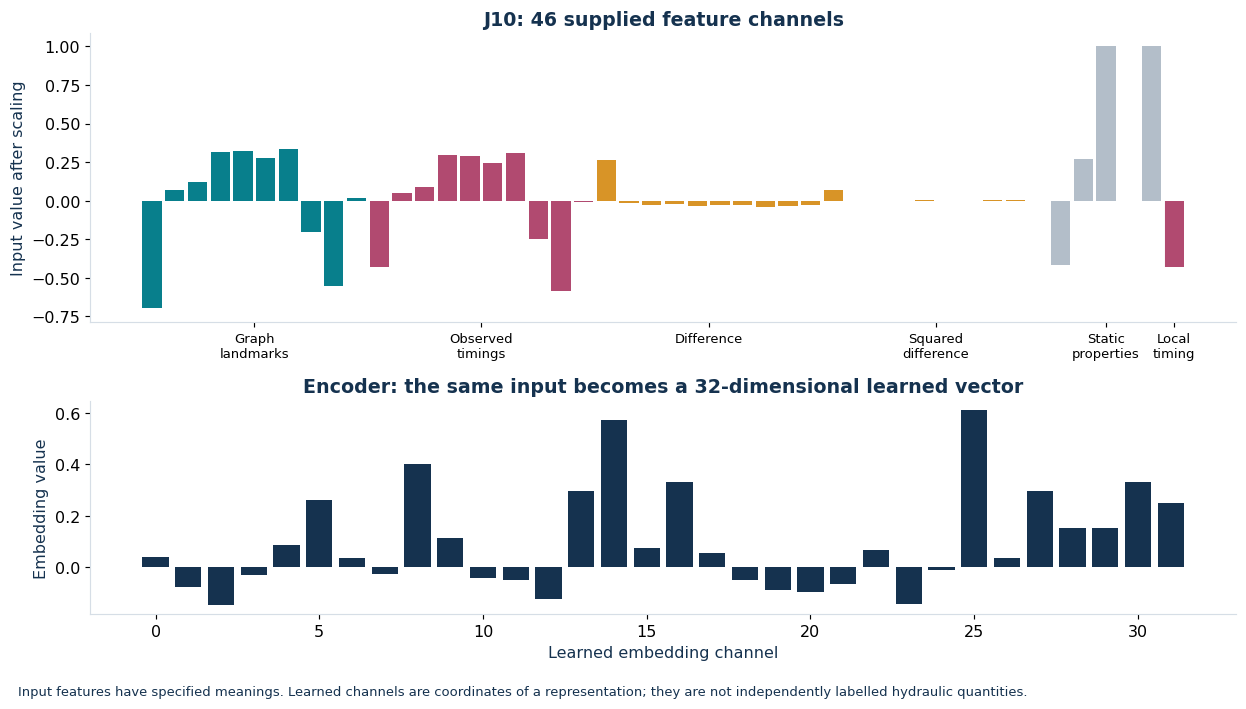

Accordion(children=(VBox(children=(HTML(value='Known travel-time landmarks and observed timing values are avai…

In [8]:
# Use the selected recorded event now that noisy observations have been introduced.
observed_event = observe_event(net, tsdata, index=20, noise_std_m=BACKGROUND_STD_M,
    jitter_ms=EXTRA_PICK_JITTER_MS, seed=42)
observation = observed_event['relative_s'][None, :]
if not np.isfinite(observation).all():
    raise ValueError('This noise setting leaves a missing arrival. Reduce BACKGROUND_STD_M for the feature walkthrough; the interactive signal explorer handles missing picks explicitly.')
fig = ui.plot_features(net, gnn, observation)
display(fig); plt.close(fig)
display(ui.panel(ui.feature_explorer(net, gnn, observation), 'Explore interactively: input features and initial embeddings'))

## 6. Message passing: receive, combine, update

### Node degree, self-connections and adjacency normalisation

For our binary, undirected graph, the adjacency entry $A_{ij}$ is 1 when nodes $i$ and $j$ are directly connected, and 0 otherwise.

The **degree** of node $i$ is the number of its directly connected neighbours:

$$
d_i=\sum_j A_{ij}.
$$

For example, if a node connects directly to three other nodes, its degree is 3. These are its one-hop neighbours.

When updating a node's embedding, we want to include information from the node itself as well as its neighbours. We therefore add an identity matrix:

$$
\widetilde A=A+I.
$$

The identity matrix has 1 on its diagonal and 0 elsewhere. Adding it creates a computational self-connection at each node. It does not add a physical pipe or change the travel-time network.

Because each node gains one self-connection, its degree in this augmented adjacency is

$$
\widetilde d_i=\sum_j\widetilde A_{ij}=d_i+1.
$$

We collect these values into a **diagonal degree matrix**:

$$
\widetilde D=
\operatorname{diag}
(\widetilde d_1,\widetilde d_2,\ldots,\widetilde d_N).
$$

The diagonal contains the augmented node degrees. Every off-diagonal entry is zero.

We can now define the normalised adjacency:

$$
\widehat A=
\widetilde D^{-1/2}\widetilde A\widetilde D^{-1/2}.
$$

Equivalently, each entry is

$$
\widehat A_{ij}
=
\frac{\widetilde A_{ij}}
{\sqrt{\widetilde d_i\widetilde d_j}}.
$$

Thus, each connection is scaled using the degrees of both nodes. This moderates the effect of differing neighbour counts when embeddings are aggregated. It is symmetric degree normalisation; its rows do not necessarily sum to 1.


A message-passing layer in this model computes

$$H^{(k+1)}=\operatorname{GELU}\!\left(H^{(k)}W_{\mathrm{self}}^{(k)}+\widehat A H^{(k)}W_{\mathrm{neighbour}}^{(k)}+b^{(k)}\right)+0.2H^{(k)}.$$

Multiplying $\widehat A H$ forms weighted combinations of each node's own embedding and its neighbours' embeddings.

,Before aggregation,Aggregated neighbours + self
channel 1,0.4117,0.3933
channel 2,0.9666,1.1162
channel 3,-0.1368,-0.1585
channel 4,-0.0009,-0.0153
channel 5,-0.1024,-0.1236
channel 6,-0.0213,-0.0509


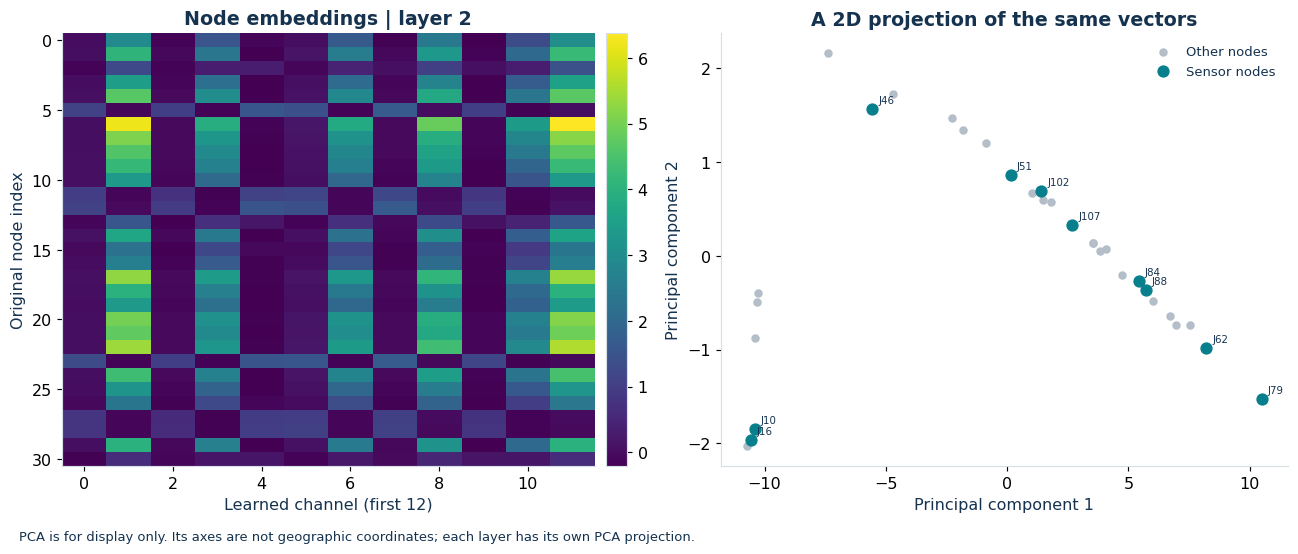

Accordion(children=(VBox(children=(HTML(value='Layer 0 is the encoder output. Each graph update combines neigh…

In [9]:
encoded = predict(gnn, observation, return_embeddings=True)
H0 = encoded['embeddings'][0][0]
Ahat = gnn.normalized_adjacency.detach().cpu().numpy()
messages = Ahat @ H0
node = net.names.index('J84')
display(pd.DataFrame({'Before aggregation': H0[node,:6],
                      'Aggregated neighbours + self': messages[node,:6]},
                     index=[f'channel {i+1}' for i in range(6)]).round(4))
fig = ui.plot_embeddings(net, gnn, observation, layer=2)
display(fig); plt.close(fig)
display(ui.panel(ui.embedding_explorer(net, gnn, observation), 'Explore interactively: layers, embeddings and aggregation'))

**Interpret the figure:** layer 0 is the encoded input, while layers 1 and 2 have received graph messages. A heatmap colour describes a learned channel value. The two-dimensional embedding scatter uses PCA for display; its axes are not map coordinates. Individual channels need not correspond to recognisable hydraulic quantities.

## 7. Two outputs describe one physical location

For each original pipe, the decoder combines the embeddings at its two endpoints, their absolute difference, observed timing information, endpoint landmarks, and pipe length and diameter. The decoder's weights are shared across pipes.

- The **classification output** assigns one score per pipe. Softmax converts eligible-pipe scores into probabilities.
- The **regression output** supplies a fraction $\widehat\xi_e\in(0,1)$ for each pipe using a sigmoid.

Choose $\widehat e=\arg\max_e p_e$, then use **that pipe's** fraction $\widehat\xi_{\widehat e}$. The distance from its original start node is $\widehat x=\widehat\xi_{\widehat e}L_{\widehat e}$. The true pipe is not given to the model at inference.

All 33 pipe columns retain their original indexing. Pipes below the source-length threshold have zero output probability but remain in graph propagation. Softmax values are model outputs, not calibrated uncertainty intervals.

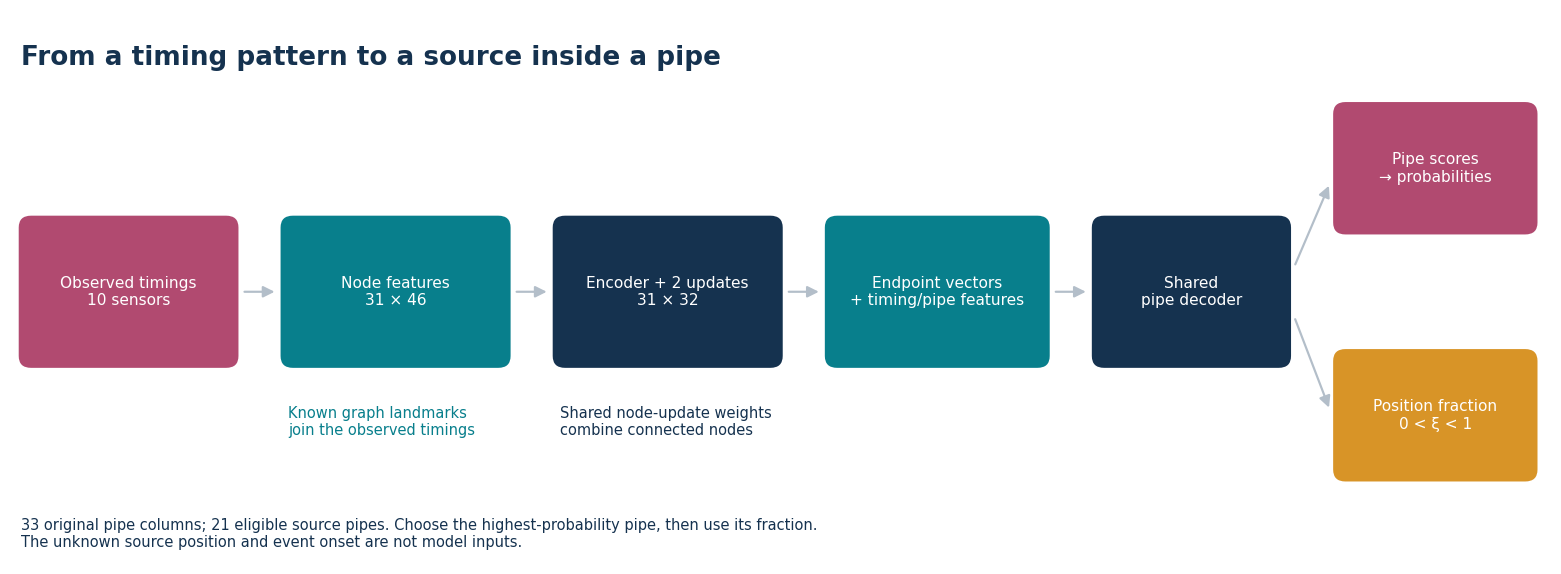

True teaching source: P7 0.212L


GNN prediction: P7 0.473L


Distance from predicted pipe start: 57.2 m


Trainable parameters: 16066


Accordion(children=(VBox(children=(HTML(value='Move a source continuously within an eligible pipe. The random …

In [10]:
fig = ui.plot_architecture(net, gnn)
display(fig); plt.close(fig)
result = predict(gnn, observation)
pred_pipe, pred_xi = int(result['pipe'][0]), float(result['xi'][0])
true_pipe = int(tsdata['pipe'][observed_event['index']])
true_xi = float(tsdata['xi'][observed_event['index']])
print('True teaching source:', net.pipe_names[true_pipe], f'{true_xi:.3f}L')
print('GNN prediction:', net.pipe_names[pred_pipe], f'{pred_xi:.3f}L')
print(f'Distance from predicted pipe start: {pred_xi*net.lengths[pred_pipe]:.1f} m')
print('Trainable parameters:', sum(p.numel() for p in gnn.parameters()))
display(ui.panel(ui.source_explorer(net, gnn), 'Explore interactively: timing pattern and GNN outputs'))

## 8. Where do the training examples come from?

Thousands of hydraulic simulations would be costly. The graph travel-time prior generates labelled **timing vectors** quickly, providing a surrogate for the first-arrival part of the physics.

For each example, choose an eligible original pipe and a position within it, compute the sensor travel times, add timestamp uncertainty and quantisation, and remove the unknown common onset. The labels are the original pipe ID and position fraction. This process does not generate full pressure waveforms.

| Split | Locations per eligible pipe | Default count | Role |
|---|---:|---:|---|
| Training | 48 | 1,008 | Fit model parameters |
| Validation | 12 | 252 | Choose the checkpoint |
| Held-out graph prior | 2 | 42 | Evaluate unseen locations |


In [11]:
sample = slice(0, 5)
raw_times = add_timing_noise(splits['train']['times'][sample], TIMING_STD_S,
    TIME_QUANTUM_S, np.random.default_rng(42))
examples = pd.DataFrame(relative_times(raw_times), columns=list(net.sensors))
examples.insert(0, 'Source fraction', splits['train']['xi'][sample])
examples.insert(0, 'Source pipe', [net.pipe_names[int(p)] for p in splits['train']['pipe'][sample]])
display(examples.round(3))

,Source pipe,Source fraction,J10,J84,J102,J107,J88,J62,J79,J46,J16,J51
0,P24,0.630,0.71,0.48,0.55,0.74,0.72,0.05,0.29,0.22,0.57,0.00
1,P24,0.706,0.71,0.49,0.54,0.74,0.74,0.02,0.26,0.21,0.57,0.00
2,P24,0.526,0.69,0.47,0.54,0.72,0.72,0.07,0.31,0.21,0.55,0.00
3,P24,0.088,0.71,0.47,0.52,0.71,0.73,0.23,0.45,0.20,0.54,0.00
4,P24,0.803,0.71,0.49,0.53,0.73,0.74,0.00,0.24,0.23,0.57,0.01


### How the model learns

For each batch, the model predicts the pipe scores and fractions. The loss combines cross-entropy for the pipe label with squared fraction error on the **true pipe during training**:

$$\mathcal L=\operatorname{CE}(p,e_{\mathrm{true}})+4\left(\widehat\xi_{e_{\mathrm{true}}}-\xi_{\mathrm{true}}\right)^2.$$

The coefficient 4 balances the two terms; fraction error is dimensionless, while our reported distance error is in metres. Backpropagation computes gradients, and Adam updates the learned weights. The graph and physical pipe properties remain fixed.

The setup cell contains the actual `train_model(...)` call. Set `RETRAIN=True` there to fit a new model. The retraining configuration uses 32 hidden channels, three message-passing layers, batch size 128 and an initial learning rate of 0.002. The supplied teaching model uses two message-passing layers. Validation controls learning-rate reductions and early stopping. The maximum is 500 epochs; 30 epochs without a sufficient validation-loss improvement stop the run. The best validation-loss checkpoint is restored.

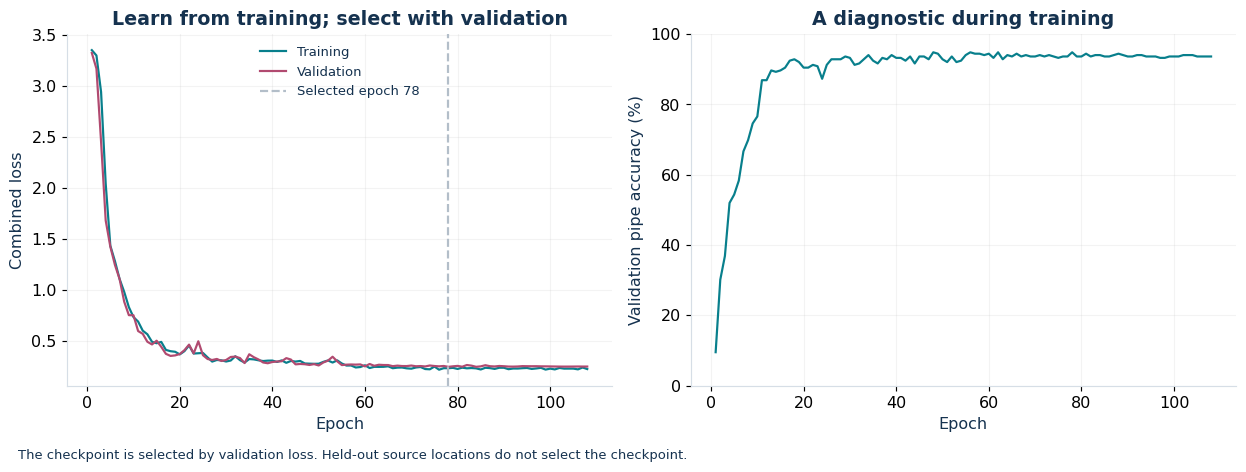

Selected validation checkpoint: epoch 78


Completed epochs: 108


In [12]:
fig = ui.plot_training(history)
display(fig); plt.close(fig)
print('Selected validation checkpoint: epoch', history.get('best_epoch', '?'))
print('Completed epochs:', history.get('completed_epochs', len(history.get('epoch', []))))

## 9. Return to the pressure signal and locate its source

- The hydraulic test events come from TSNet's method-of-characteristics solver. 
- For each event, WNTR inserts a temporary junction inside an original pipe, TSNet applies a burst there, and pressure histories are recorded at the original junctions.
- We now extract arrivals from the stored **100 Hz** signals, form the timing features, and predict the original pipe and fraction.
- The prepared record contains **21 events**, one in each eligible pipe.
- The GNN has learned from graph-derived timing examples. Testing it on these hydraulic signals checks how that learned mapping behaves with a more complete wave simulation.

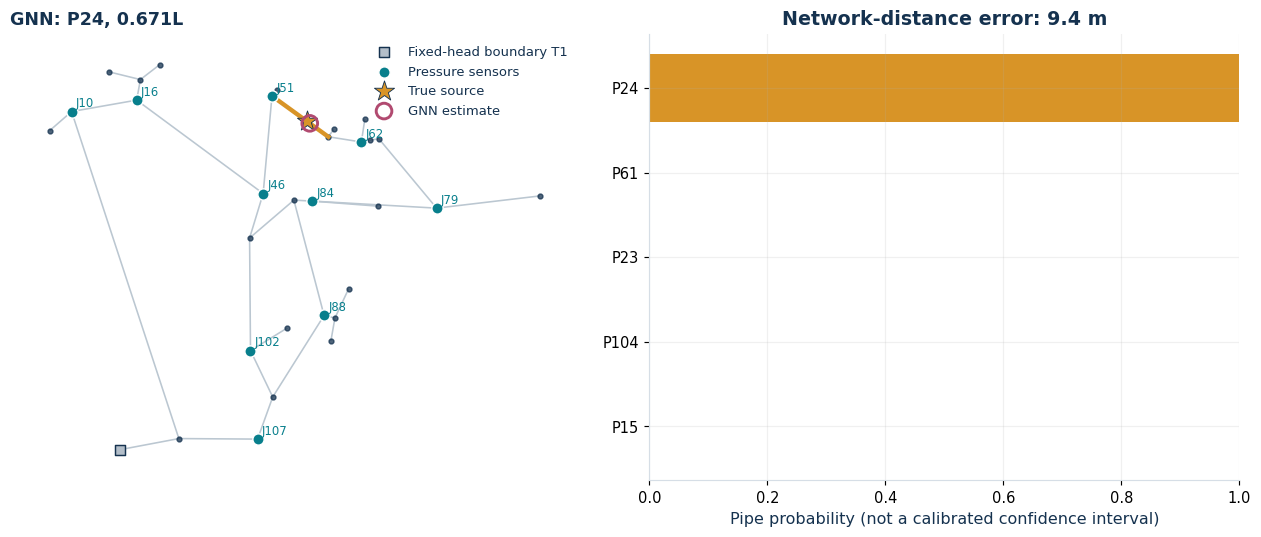

Accordion(children=(VBox(children=(HTML(value='<b>Two distinct uncertainty sources.</b> Noise σ changes pressu…

In [13]:
fig = signals.plot_localisation(net, tsdata, gnn, index=0,
    noise_std_m=BACKGROUND_STD_M, jitter_ms=EXTRA_PICK_JITTER_MS, seed=42)
display(fig); plt.close(fig)
display(ui.panel(signals.uncertainty_explorer(net, tsdata, model=gnn, noise_std_m=BACKGROUND_STD_M, jitter_ms=EXTRA_PICK_JITTER_MS, seed=42), 'Explore interactively: signals, picks and predicted source'))

## 10. Interpret the two results

**Pipe accuracy:** the percentage of events assigned to their correct original pipe.

**Mean network-distance error:** the shortest physical route between the true and predicted continuous source positions, averaged over events. Wrong-pipe predictions are included. The direct along-pipe distance is also considered when both points lie on the same pipe.

A wrong pipe near a junction can still give a small distance error. Conversely, selecting the correct pipe does not guarantee a good position estimate. Inspect both numbers and individual examples.

The report separates held-out graph-derived observations, clean hydraulic signal picks, and hydraulic observations with background noise plus extra picking uncertainty. Detection coverage is shown if a sensor fails to produce a usable arrival. An unlocalised event cannot be assigned a fabricated distance error.

TSNet sources: retained 21/21 cached events; excluded 0 below 100 m.


,Events,Localised events,Pipe accuracy (%),Mean network distance error (m)
Evaluation,,,,
Graph-prior held-out sources,42,42,97.62,26.16
TSNet signals: clean,21,21,100.00,21.18
TSNet signals: noise and picking uncertainty,21,21,90.48,32.20


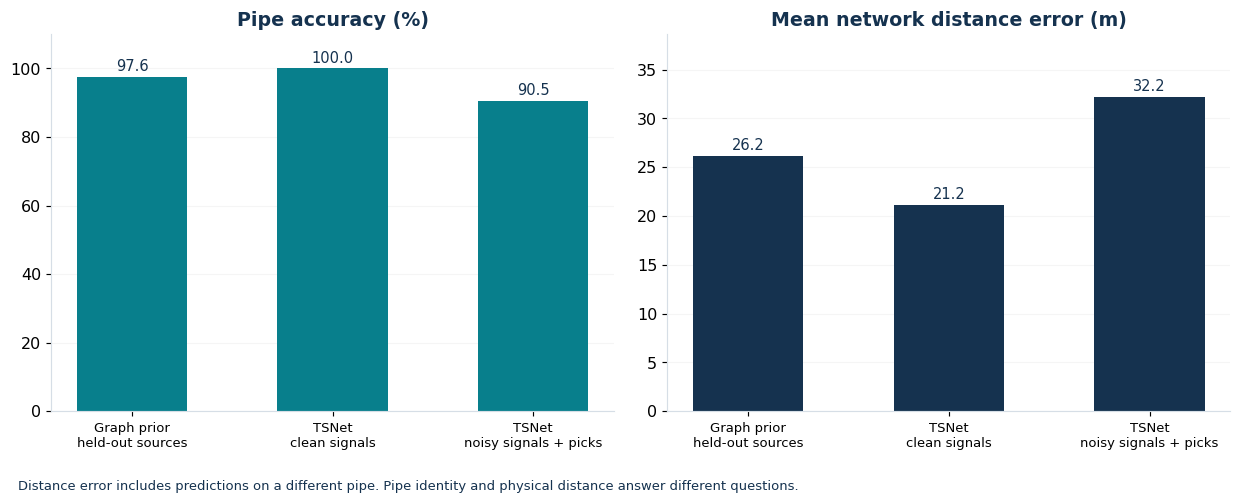

In [14]:
report = evaluate(net, splits, gnn, sigma=TIMING_STD_S, quantum=TIME_QUANTUM_S,
                  pressure_noise_std_m=BACKGROUND_STD_M, extra_jitter_ms=EXTRA_PICK_JITTER_MS)
display(ui.metrics_table(report))
fig = ui.plot_metrics(report)
display(fig); plt.close(fig)

## 11. Optional: run a new burst locally

This lab runs only after you press its simulation button. It uses the locally installed TSNet package, simulates the burst and its matched no-burst reference, and applies the GNN to the picked arrivals.

The position fraction is measured from the original pipe start. The **opening time** controls how quickly the burst develops. The coefficient $C_b$ enters $Q_b=C_b\sqrt{H-z}$ and has units $\mathrm{m^3\,s^{-1}\,m^{-1/2}}$ for positive pressure head.

The demonstration starts the burst at 0.5 s in a 3 s record, but the GNN is not given this onset. The default coefficient corresponds to 0.001 m³/s at 40 m pressure head. Very short split segments require smaller simulation time steps. New simulations can take minutes; use the cached signals during the one-hour session.

In [15]:
display(ui.panel(ui.burst_lab(net, gnn), 'Optional local TSNet burst laboratory'))

Accordion(children=(VBox(children=(HTML(value='Optional exploration after the lecture. No solver is started wh…

## 12. Key References
- Waqar, M., Ghidaoui, M. S. (2026). Travel-time-supervised graph learning for passive transient source localization in water distribution networks. Journal of Hydrodynamics, 38(6) – Springer Nature (forthcoming)
- Waqar, M., Ghidaoui, M. S. (2026). Passive Transient Source Localization in Water Distribution Network using Graph Neural Networks. In proceedings of the 16th International Conference on
Hydrodynamics (ICHD 2026), April 15-18, 2026, Macao, China ([Link](https://researchportal.hkust.edu.hk/en/publications/passive-transient-source-localization-in-water-distribution-netwo/))
- [Kipf and Welling (2017)](https://arxiv.org/abs/1609.02907) introduce graph convolution,
- [Xing and Sela (2020)](https://doi.org/10.1016/j.advengsoft.2020.102884) describe TSNet, the hydraulic simulator used here.

Our prediction has two parts: **which original pipe** and **the position within that pipe**. We return to the hidden source after constructing those ingredients. Full references are in [REFERENCES.md](REFERENCES.md); and [CITATION.cff](CITATION.cff) to cite this tutorial.

## 13. Homework (expected time = 5 hours)
1. Retrain the model with numbers of sensors = [3, 5, 8] and compare the results with the case presented here, with Ns = 10.
2. Submission file should contain
   - a summary of training prameters described in (1) together with model architecture and hyperparameters model training curves,
   - model training curves (as in Section 8)
   - model performance (as in Section 10)
   - a short summary on your findings.
3. Submit your solution at mwaqar@hkmu.edu.hk
   